<a href="https://colab.research.google.com/github/buntyedutainer/student-performance-ai/blob/main/Notebook1_Data_Understanding.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# Upload the file into Colab
from google.colab import files
files.upload()   # pick student-mat.csv

Saving student-mat.csv to student-mat.csv


{'student-mat.csv': b'school;sex;age;address;famsize;Pstatus;Medu;Fedu;Mjob;Fjob;reason;guardian;traveltime;studytime;failures;schoolsup;famsup;paid;activities;nursery;higher;internet;romantic;famrel;freetime;goout;Dalc;Walc;health;absences;G1;G2;G3\n"GP";"F";18;"U";"GT3";"A";4;4;"at_home";"teacher";"course";"mother";2;2;0;"yes";"no";"no";"no";"yes";"yes";"no";"no";4;3;4;1;1;3;6;"5";"6";6\n"GP";"F";17;"U";"GT3";"T";1;1;"at_home";"other";"course";"father";1;2;0;"no";"yes";"no";"no";"no";"yes";"yes";"no";5;3;3;1;1;3;4;"5";"5";6\n"GP";"F";15;"U";"LE3";"T";1;1;"at_home";"other";"other";"mother";1;2;3;"yes";"no";"yes";"no";"yes";"yes";"yes";"no";4;3;2;2;3;3;10;"7";"8";10\n"GP";"F";15;"U";"GT3";"T";4;2;"health";"services";"home";"mother";1;3;0;"no";"yes";"yes";"yes";"yes";"yes";"yes";"yes";3;2;2;1;1;5;2;"15";"14";15\n"GP";"F";16;"U";"GT3";"T";3;3;"other";"other";"home";"father";1;2;0;"no";"yes";"yes";"no";"yes";"yes";"no";"no";4;3;2;1;2;5;4;"6";"10";10\n"GP";"M";16;"U";"LE3";"T";4;3;"service

In [3]:
# Cell 1: setup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
df = pd.read_csv("student-mat.csv", sep=";")
print("Shape:", df.shape)

Shape: (395, 33)


In [4]:
# Cell 2: data types, split into numeric and categorical
num_cols = df.select_dtypes(include="number").columns.tolist()
cat_cols = df.select_dtypes(exclude="number").columns.tolist()

print(f"Numeric columns ({len(num_cols)}):", num_cols)
print()
print(f"Categorical columns ({len(cat_cols)}):", cat_cols)

Numeric columns (16): ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Categorical columns (17): ['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']


In [5]:
# Cell 3: missing values and duplicates
print("Missing values per column (only showing columns with any):")
missing = df.isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else "None, the dataset is complete")

print("\nDuplicate rows:", df.duplicated().sum())

Missing values per column (only showing columns with any):
None, the dataset is complete

Duplicate rows: 0


In [6]:
# Cell 4: what values do the categorical columns contain?
for c in cat_cols:
    print(f"{c:12s} -> {sorted(df[c].unique())}")

school       -> ['GP', 'MS']
sex          -> ['F', 'M']
address      -> ['R', 'U']
famsize      -> ['GT3', 'LE3']
Pstatus      -> ['A', 'T']
Mjob         -> ['at_home', 'health', 'other', 'services', 'teacher']
Fjob         -> ['at_home', 'health', 'other', 'services', 'teacher']
reason       -> ['course', 'home', 'other', 'reputation']
guardian     -> ['father', 'mother', 'other']
schoolsup    -> ['no', 'yes']
famsup       -> ['no', 'yes']
paid         -> ['no', 'yes']
activities   -> ['no', 'yes']
nursery      -> ['no', 'yes']
higher       -> ['no', 'yes']
internet     -> ['no', 'yes']
romantic     -> ['no', 'yes']


In [7]:
# Cell 5: outlier check using the IQR rule
def count_outliers(series):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return ((series < low) | (series > high)).sum()

outliers = pd.Series({c: count_outliers(df[c]) for c in num_cols}).sort_values(ascending=False)
print(outliers[outliers > 0])

failures      83
studytime     27
famrel        26
freetime      19
Dalc          18
absences      15
G2            13
traveltime     8
Fedu           2
age            1
dtype: int64


In [8]:
# Cell 6: build a data dictionary
descriptions = {
    "school": "School attended (GP or MS)",
    "sex": "Student's sex (F or M)",
    "age": "Age in years (15-22)",
    "address": "Home address type (U = urban, R = rural)",
    "famsize": "Family size (LE3 = 3 or fewer, GT3 = more than 3)",
    "Pstatus": "Parents living together (T) or apart (A)",
    "Medu": "Mother's education (0-4)",
    "Fedu": "Father's education (0-4)",
    "Mjob": "Mother's job category",
    "Fjob": "Father's job category",
    "reason": "Reason for choosing this school",
    "guardian": "Student's guardian",
    "traveltime": "Home to school travel time (1-4)",
    "studytime": "Weekly study time (1-4)",
    "failures": "Number of past class failures",
    "schoolsup": "Extra educational support from school",
    "famsup": "Family educational support",
    "paid": "Paid extra classes in the subject",
    "activities": "Extracurricular activities",
    "nursery": "Attended nursery school",
    "higher": "Wants to take higher education",
    "internet": "Internet access at home",
    "romantic": "In a romantic relationship",
    "famrel": "Quality of family relationships (1-5)",
    "freetime": "Free time after school (1-5)",
    "goout": "Going out with friends (1-5)",
    "Dalc": "Weekday alcohol consumption (1-5)",
    "Walc": "Weekend alcohol consumption (1-5)",
    "health": "Current health status (1-5)",
    "absences": "Number of school absences",
    "G1": "First period grade (0-20)",
    "G2": "Second period grade (0-20)",
    "G3": "Final grade (0-20), TARGET",
}

dictionary = pd.DataFrame({
    "column": df.columns,
    "type": ["numeric" if c in num_cols else "categorical" for c in df.columns],
    "description": [descriptions[c] for c in df.columns],
    "example": [df[c].iloc[0] for c in df.columns],
})
dictionary.to_csv("data_dictionary.csv", index=False)
dictionary

,column,type,description,example
0,school,categorical,School attended (GP or MS),GP
1,sex,categorical,Student's sex (F or M),F
2,age,numeric,Age in years (15-22),18
3,address,categorical,"Home address type (U = urban, R = rural)",U
4,famsize,categorical,"Family size (LE3 = 3 or fewer, GT3 = more than 3)",GT3
5,Pstatus,categorical,Parents living together (T) or apart (A),A
6,Medu,numeric,Mother's education (0-4),4
7,Fedu,numeric,Father's education (0-4),4
8,Mjob,categorical,Mother's job category,at_home
9,Fjob,categorical,Father's job category,teacher


In [9]:
# Cell 7: a one-screen summary of the dataset
summary = {
    "Rows": df.shape[0],
    "Columns": df.shape[1],
    "Numeric columns": len(num_cols),
    "Categorical columns": len(cat_cols),
    "Missing values": int(df.isnull().sum().sum()),
    "Duplicate rows": int(df.duplicated().sum()),
    "Average final grade": round(df["G3"].mean(), 2),
    "Pass rate (G3 >= 10)": round((df["G3"] >= 10).mean(), 3),
    "Students with G3 = 0": int((df["G3"] == 0).sum()),
    "Correlation G2-G3": round(df["G2"].corr(df["G3"]), 2),
    "Correlation G1-G3": round(df["G1"].corr(df["G3"]), 2),
    "Correlation failures-G3": round(df["failures"].corr(df["G3"]), 2),
}
for k, v in summary.items():
    print(f"{k:28s}{v}")

Rows                        395
Columns                     33
Numeric columns             16
Categorical columns         17
Missing values              0
Duplicate rows              0
Average final grade         10.42
Pass rate (G3 >= 10)        0.671
Students with G3 = 0        38
Correlation G2-G3           0.9
Correlation G1-G3           0.8
Correlation failures-G3     -0.36


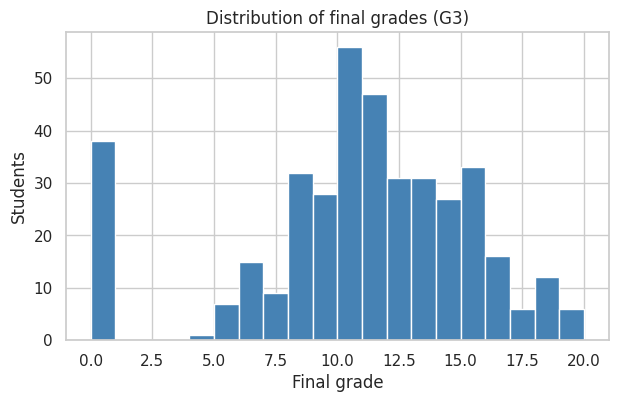

In [10]:
# Cell 8: save the three best figures for your report
fig, ax = plt.subplots(figsize=(7, 4))
df["G3"].hist(bins=20, ax=ax, color="steelblue", edgecolor="white")
ax.set_title("Distribution of final grades (G3)")
ax.set_xlabel("Final grade")
ax.set_ylabel("Students")
fig.savefig("g3_distribution.png", dpi=150, bbox_inches="tight")
plt.show()